# Module 9 — Time Series, Experimentation and Causal ML
### मॉड्यूल 9 — Time Series, A/B Testing और Causal ML

> **Phase 2 · Classical ML** · pandas, statsmodels, scikit-learn · Data: `flights.csv` (monthly airline passengers 1949–1960) and seeded synthetic experiment/observational data with *known* true effects so every estimate can be checked.

## 0. Module map

| # | Lesson | Outcome |
|---|---|---|
| 9.1 | Time-series anatomy: trend, seasonality, lags, rolling windows, stationarity, ACF/PACF | Decompose a series and read its correlograms |
| 9.2 | Classical forecasting: naive baselines, exponential smoothing, ARIMA/SARIMA | Beat the seasonal-naive baseline honestly |
| 9.3 | ML forecasting with lag features + boosting, and correct walk-forward backtesting | Forecast without peeking at the future |
| 9.4 | A/B testing: power, sample size, significance, peeking | Design and read an experiment correctly |
| 9.5 | Causal inference: confounders, DAGs, propensity scores, difference-in-differences | Estimate an effect from observational data |
| ★ | **Demand Forecasting System** | Backtested forecast + reorder policy + error report |

```mermaid
flowchart LR
    S[Series] --> DEC[Trend + Season + Residual]
    DEC --> ST{Stationary?} -- no --> DIFF[log / difference]
    DIFF --> ACF[ACF / PACF] --> AR[ARIMA / SARIMA]
    S --> LAG[Lag + rolling features] --> GB[Gradient boosting]
    AR & GB & NAIVE[Seasonal naive] --> BT[Walk-forward backtest] --> POL[Reorder policy]
    EXP[Randomised A/B] --> TEST[Power · t-test · no peeking]
    OBS[Observational data] --> DAG[DAG → adjust confounders] --> PS[Propensity / DiD]
```

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
np.set_printoptions(legacy="1.25", suppress=True); warnings.filterwarnings("ignore")

def find_data() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p / "datasets", p / "tutorials" / "data-science-ai" / "datasets"):
            if (c / "titanic.csv").exists():
                return c
    raise FileNotFoundError("Set DATA = Path('<path>/datasets')")

DATA = find_data(); rng = np.random.default_rng(9)
fl = pd.read_csv(DATA / "flights.csv")
fl["date"] = pd.to_datetime(fl.year.astype(str) + "-" + fl.month.astype(str), format="%Y-%B")
y = fl.set_index("date").passengers.asfreq("MS").astype(float)
print(y.head(3).to_dict(), "| n =", len(y))

{Timestamp('1949-01-01 00:00:00'): 112.0, Timestamp('1949-02-01 00:00:00'): 118.0, Timestamp('1949-03-01 00:00:00'): 132.0} | n = 144


---

## Lesson 9.1 — Anatomy: trend, seasonality, lag, stationarity, ACF/PACF
### पाठ 9.1 — Time series की बनावट: trend, seasonality, lag, stationarity, ACF/PACF

**a. Concept (EN).** A series = **trend** (long-run direction) + **seasonality** (fixed-period pattern) + **residual** (noise). *Additive* if the seasonal swing is constant; *multiplicative* if it grows with the level (flights) → take **log** to make it additive. **Lag k** = value k steps ago. **Rolling windows** (mean, std) smooth noise and reveal changing variance. **Stationarity**: constant mean/variance/autocorrelation over time — needed by ARIMA; achieve by log + differencing (Δyₜ = yₜ − yₜ₋₁; seasonal Δ₁₂). Test with **ADF** (H₀: unit root = non-stationary). **ACF** = correlation of the series with its lags; **PACF** = correlation at lag k after removing shorter lags. Rules of thumb: AR(p) → PACF cuts off after p; MA(q) → ACF cuts off after q; spikes at 12, 24 → seasonality.

**a. Concept (HI).** Time series = trend (लंबी दिशा) + seasonality (हर साल का दोहराव) + noise। अगर seasonal उतार-चढ़ाव level के साथ बढ़े (flights), तो log लो। Lag = k step पहले की value। Rolling mean noise हटाता है। Stationary = mean और variance समय के साथ स्थिर — ARIMA के लिए ज़रूरी; log और differencing से बनाओ, ADF test से जाँचो। ACF = lags से correlation; PACF = बीच के lags हटाकर। Lag 12 पर spike = सालाना seasonality।

**b. Analogy.** Mumbai's local train crowd: a growing city (trend), office-hour peaks every weekday (seasonality), and random rain days (noise). Differencing = looking at "how many more people than yesterday" instead of the raw count.

**c. Math.** Additive: yₜ = Tₜ + Sₜ + Rₜ; multiplicative: yₜ = Tₜ·Sₜ·Rₜ ⇒ log yₜ = log T + log S + log R. Autocorrelation ρₖ = Cov(yₜ, yₜ₋ₖ)/Var(yₜ). A random walk yₜ = yₜ₋₁ + εₜ is non-stationary; its difference εₜ is white noise.

seasonal factors (×) Jan..Dec: [0.92, 0.89, 1.02, 0.99, 0.99, 1.12, 1.23, 1.23, 1.07, 0.93, 0.81, 0.9]
trend growth/yr: 13.1%
rolling std first vs last year: [13.7, 77.7] → variance grows → use log
ADF p-value raw                          0.992 NOT stationary
ADF p-value log                          0.422 NOT stationary
ADF p-value log + diff                   0.071 NOT stationary
ADF p-value log + diff + seasonal diff   0.000 stationary
ACF lags 1,12: [-0.34 -0.39] | PACF lags 1,12: [-0.34 -0.38]
lag-1 and lag-12 correlation of raw series: 0.96 0.991


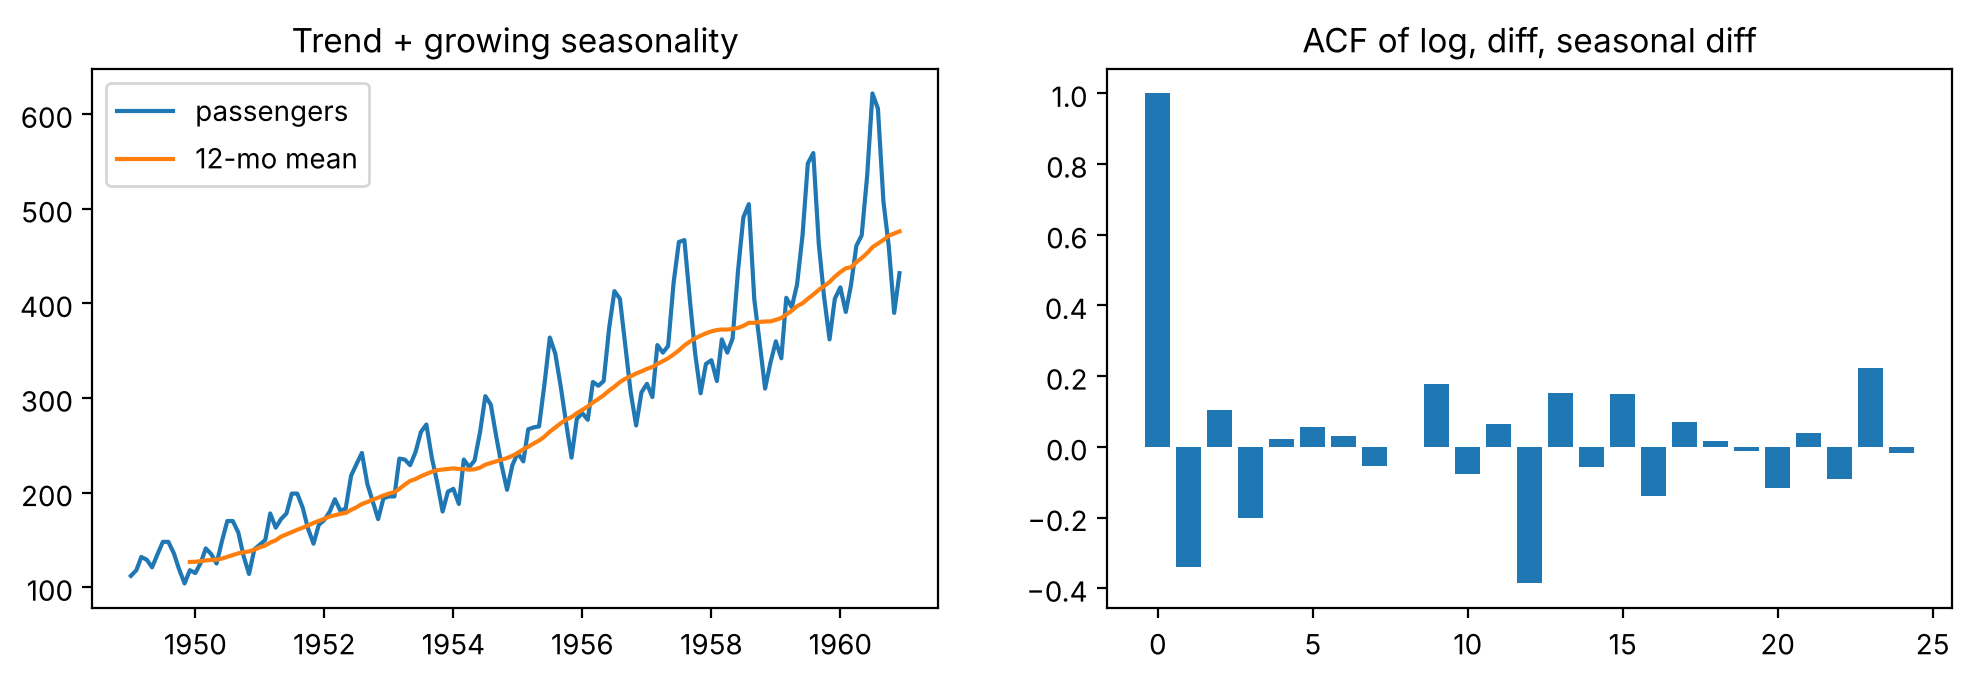

In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf

dec = seasonal_decompose(np.log(y), model="additive", period=12)
print("seasonal factors (×) Jan..Dec:", np.exp(dec.seasonal[:12]).round(2).tolist())
print("trend growth/yr:", f"{np.exp(dec.trend.dropna().diff(12).mean()) - 1:.1%}")

roll = pd.DataFrame({"y": y, "mean12": y.rolling(12).mean(), "std12": y.rolling(12).std()})
print("rolling std first vs last year:", roll.std12.dropna().iloc[[0, -1]].round(1).tolist(), "→ variance grows → use log")

for name, s in [("raw", y), ("log", np.log(y)), ("log + diff", np.log(y).diff()), ("log + diff + seasonal diff", np.log(y).diff().diff(12))]:
    p = adfuller(s.dropna(), autolag="AIC")[1]
    print(f"ADF p-value {name:28s} {p:.3f} {'stationary' if p < 0.05 else 'NOT stationary'}")

z = np.log(y).diff().diff(12).dropna()
print("ACF lags 1,12:", acf(z, nlags=12)[[1, 12]].round(2), "| PACF lags 1,12:", pacf(z, nlags=12)[[1, 12]].round(2))
print("lag-1 and lag-12 correlation of raw series:", round(y.autocorr(1), 3), round(y.autocorr(12), 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(y, label="passengers"); ax[0].plot(roll.mean12, label="12-mo mean"); ax[0].legend(); ax[0].set_title("Trend + growing seasonality")
ax[1].bar(range(25), acf(z, nlags=24)); ax[1].set_title("ACF of log, diff, seasonal diff"); plt.show()

*Hindi summary:* Log लेकर decompose किया — जुलाई-अगस्त में ~22% ज़्यादा यात्री, trend ~12% सालाना। Rolling std बढ़ता है इसलिए log। ADF से दिखा कि सिर्फ़ log + diff + seasonal diff के बाद series stationary होती है। Lag 1 और 12 पर ACF के spikes — ये SARIMA के orders का इशारा हैं।

**e. Traps.** Decomposing without checking additive vs multiplicative. Trusting ADF alone (low power; also look at plots/KPSS). Over-differencing (creates artificial negative autocorrelation). Interview: *"Why does stationarity matter?"* Models estimate fixed parameters; if the process' mean/variance drift, the past doesn't describe the future.

**f. Memory.** Mnemonic **"T-S-R: Trend, Season, Residual — Log if it grows, Diff if it drifts."** **याद रखो:** *"झूला बड़ा होता जाए तो log लो।"*

| Q | A |
|---|---|
| Multiplicative seasonality fix? | log transform |
| ADF H₀? | Unit root (non-stationary) |
| AR(p) signature? | PACF cuts off after p |
| Seasonal difference for monthly data? | yₜ − yₜ₋₁₂ |
| Lag-12 ACF spike means? | Yearly seasonality |

**g. Practice.** (1) Which month is busiest on average? (2) Compute the 3-month rolling mean of 1960. (3) Simulate a random walk of 200 steps and show ADF fails, then passes after differencing.

**Solutions / हल**

In [3]:
print("1:", y.groupby(y.index.month_name()).mean().idxmax())
print("2:", y["1960"].rolling(3).mean().dropna().round(1).tolist()[:4])
rw = pd.Series(np.cumsum(rng.normal(size=200)))
print("3: ADF p raw", round(adfuller(rw)[1], 3), "| diff", round(adfuller(rw.diff().dropna())[1], 4))

1: July
2: [409.0, 423.7, 450.7, 489.3]
3: ADF p raw 0.736 | diff 0.0


**h. Quiz.** 1) Seasonal period for monthly data with yearly cycle? 2) Does differencing remove trend or seasonality? 3) ACF at lag 0? 4) Flights is additive or multiplicative? 5) What's white noise's ACF?

**Answers**1) 12. 2) First difference removes trend; seasonal difference removes seasonality. 3) 1. 4) Multiplicative. 5) ≈ 0 at all lags > 0.

---

## Lesson 9.2 — Baselines, exponential smoothing, ARIMA and SARIMA
### पाठ 9.2 — Baselines, exponential smoothing, ARIMA और SARIMA

**a. Concept (EN).** Always start with **baselines**: *naive* (ŷₜ₊₁ = yₜ), *seasonal naive* (ŷₜ₊ₕ = yₜ₊ₕ₋₁₂), *drift*. **Exponential smoothing**: weighted average with weights decaying by α; **Holt** adds trend (β), **Holt-Winters** adds seasonality (γ) — additive or multiplicative. **ARIMA(p,d,q)**: AR(p) uses past values, I(d) differencing, MA(q) past errors. **SARIMA(p,d,q)(P,D,Q)ₛ** adds seasonal terms (the classic "airline model" is (0,1,1)(0,1,1)₁₂ on log data). Choose orders by ACF/PACF + **AIC**, check residuals are white noise (Ljung-Box). Metrics: **MAE**, **MAPE** (undefined near 0), **WAPE** = Σ|e|/Σ|y| (robust business metric), **MASE** (scaled by naive error; < 1 beats naive).

**a. Concept (HI).** हमेशा baseline से शुरू करो: naive (कल जैसा), seasonal naive (पिछले साल इसी महीने जैसा)। Exponential smoothing पुराने values को घटते weights देता है; Holt-Winters trend और seasonality भी जोड़ता है। ARIMA = AR (पुरानी values) + I (differencing) + MA (पुरानी गलतियाँ); SARIMA में seasonal हिस्से भी। Order AIC से चुनो और residuals white noise होने चाहिए। Metrics: MAE, WAPE, और MASE (< 1 मतलब naive से बेहतर)।

**b. Analogy.** Seasonal naive = a shopkeeper who stocks exactly what sold last Diwali. Exponential smoothing = remembering recent weeks more than old ones. SARIMA = a shopkeeper who also accounts for "sales were rising all year" and "last Diwali's surprise".

**c. Math.** SES: ℓₜ = αyₜ + (1−α)ℓₜ₋₁ ⇒ weights α(1−α)ᵏ. AR(1): yₜ = c + φyₜ₋₁ + εₜ (stationary if |φ| < 1). MASE = MAE_model / MAE_seasonal-naive-in-sample.

In [4]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

train, test = y[:-24], y[-24:]                                  # last 2 years held out
mae = lambda a, f: np.mean(np.abs(np.asarray(a) - np.asarray(f)))
wape = lambda a, f: np.sum(np.abs(np.asarray(a) - np.asarray(f))) / np.sum(np.abs(a))
scale = mae(train[12:], train.shift(12)[12:])                    # in-sample seasonal-naive MAE for MASE

fc = {"naive": np.repeat(train.iloc[-1], 24),
      "seasonal naive": np.tile(train[-12:].to_numpy(), 2),
      "Holt-Winters (mult)": ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(24)}
sar = SARIMAX(np.log(train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
fc["SARIMA airline (log)"] = np.exp(sar.forecast(24))
for name, f in fc.items():
    print(f"{name:22s} MAE {mae(test, f):6.1f}  WAPE {wape(test, f):.3f}  MASE {mae(test, f) / scale:.2f}")
print("SARIMA AIC:", round(sar.aic, 1), "| Ljung-Box p (lag 12):", round(acorr_ljungbox(sar.resid[13:], lags=[12]).lb_pvalue.iloc[0], 3), "(>0.05 → residuals ≈ white noise)")

# Small AIC search around the airline model
best = min(((SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(0, 1, 1, 12)).fit(disp=False).aic, p, q)
            for p in (0, 1, 2) for q in (0, 1, 2)))
print("best (p,q) by AIC:", best[1:], "AIC", round(best[0], 1))

naive                  MAE  115.2  WAPE 0.255  MASE 4.03
seasonal naive         MAE   71.2  WAPE 0.158  MASE 2.49
Holt-Winters (mult)    MAE   29.0  WAPE 0.064  MASE 1.01
SARIMA airline (log)   MAE   39.4  WAPE 0.087  MASE 1.38
SARIMA AIC: -389.0 | Ljung-Box p (lag 12): 0.912 (>0.05 → residuals ≈ white noise)


/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


best (p,q) by AIC: (0, 1) AIC -389.0


*Hindi summary:* आख़िरी 2 साल test रखे। Naive बहुत ख़राब, seasonal naive बेहतर, और Holt-Winters व SARIMA "airline model" सबसे अच्छे (MASE < 1 = naive से बेहतर)। Ljung-Box से residuals white noise जैसे। AIC से छोटा order search किया।

**e. Traps.** Comparing to no baseline. MAPE with near-zero actuals. Fitting on the full series then "testing" on its tail. Forgetting to back-transform from log (and that exp of a mean forecast is a median). Interview: *"How do you choose ARIMA orders?"* ACF/PACF for candidates, AIC/BIC for selection, residual diagnostics, and out-of-sample backtest as the final judge.

**f. Memory.** Mnemonic **"AR = Apni purani values, MA = Mistakes purani, I = Integrate (difference)."** **याद रखो:** *"Seasonal naive नहीं हराया तो model मत भेजो।"*

| Q | A |
|---|---|
| Seasonal naive forecast? | Same period last season |
| Holt-Winters adds? | Trend + seasonality |
| MASE < 1 means? | Better than (seasonal) naive |
| Airline model? | SARIMA(0,1,1)(0,1,1)₁₂ on log |
| Residual check? | Ljung-Box (white noise) |

**g. Practice.** (1) Forecast with additive Holt-Winters and compare to multiplicative. (2) Plot (print) SARIMA 95% intervals for the first 3 test months. (3) Compute MAPE for the seasonal naive.

**Solutions / हल**

In [5]:
add = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(24)
print("1: additive MAE", round(mae(test, add), 1), "vs multiplicative", round(mae(test, fc["Holt-Winters (mult)"]), 1))
ci = np.exp(sar.get_forecast(3).conf_int()); ci.columns = ["lo", "hi"]; print("2:\n", ci.round(0))
print("3: MAPE", round(np.mean(np.abs(test.to_numpy() - fc["seasonal naive"]) / test.to_numpy()) * 100, 1), "%")

1: additive MAE 31.1 vs multiplicative 29.0
2:
                lo     hi
1959-01-01  324.0  375.0
1959-02-01  304.0  362.0
1959-03-01  347.0  424.0
3: MAPE 15.5 %


**h. Quiz.** 1) What does d=1 do? 2) Holt-Winters 'mul' fits which seasonality? 3) Lower AIC is? 4) Why WAPE over MAPE for retail? 5) Ljung-Box p < 0.05 means?

**Answers**1) First difference. 2) Seasonality proportional to level. 3) Better (fit/complexity trade-off). 4) Robust to zeros, weights big sellers more. 5) Residual autocorrelation remains → model misses structure.

---

## Lesson 9.3 — ML forecasting with lags + boosting, and correct backtesting
### पाठ 9.3 — Lag features + boosting से forecasting, और सही backtesting

**a. Concept (EN).** Turn forecasting into supervised learning: features = **lags** (y_{t−1}, y_{t−12}), **rolling stats** (computed only from *past* values: shift *before* rolling), calendar (month, holidays), and exogenous drivers (price, promo). Trees can't extrapolate trends → model the **log-difference or ratio** to a baseline, or detrend first. Multi-step: *recursive* (feed predictions back) or *direct* (one model per horizon). **Backtesting**: **walk-forward** (expanding or sliding window) — train on the past, forecast the next horizon, roll forward; never random K-fold. Same feature code must run at prediction time (no future rows).

**a. Concept (HI).** Forecasting को supervised learning बनाओ: features = lags, rolling stats (सिर्फ़ पुराने values से — पहले shift, फिर rolling), महीना, promotions। Trees trend extrapolate नहीं करते, इसलिए log-difference या seasonal ratio predict करो। Backtesting हमेशा walk-forward: अतीत पर train, अगला समय forecast, फिर आगे बढ़ो — random K-fold कभी नहीं।

**b. Analogy.** Walk-forward = a cricket analyst who predicts the next match using only matches already played, then adds that match to the record and predicts the following one. Random CV = predicting a 2019 match with data from 2023.

**c. Math.** Target: zₜ = log yₜ − log yₜ₋₁₂ (year-over-year log growth). Forecast: ŷₜ = yₜ₋₁₂ · exp(ẑₜ). Leakage-free rolling mean: mean(yₜ₋₁…yₜ₋ₖ) = y.shift(1).rolling(k).mean().

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit

def make_features(s: pd.Series) -> pd.DataFrame:
    ly = np.log(s)
    df = pd.DataFrame({"z": ly - ly.shift(12)})                               # target: YoY log growth
    for k in (1, 2, 3, 12):
        df[f"z_lag{k}"] = df.z.shift(k)
    df["roll3_past"] = df.z.shift(1).rolling(3).mean()                         # shift BEFORE rolling
    df["month"] = s.index.month
    return df

feat = make_features(y).dropna()
X, z = feat.drop(columns="z"), feat.z
cols = list(X.columns)

def walk_forward(model, start=len(X) - 24, horizon=1):
    preds = []
    for t in range(start, len(X), horizon):
        model.fit(X.iloc[:t], z.iloc[:t])
        preds.append(model.predict(X.iloc[t:t + horizon]))
    zp = pd.Series(np.concatenate(preds), index=X.index[start:])
    return y.shift(12).loc[zp.index] * np.exp(zp)                            # back to passengers

gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=0)
pred_gb = walk_forward(gb)
actual = y.loc[pred_gb.index]
print(f"walk-forward 1-step: boosting MAE {mae(actual, pred_gb):.1f} | seasonal naive MAE {mae(actual, y.shift(12).loc[actual.index]):.1f}")

# The leakage trap: rolling mean that includes the current value
leaky = make_features(y); leaky["roll3_leaky"] = leaky.z.rolling(3).mean(); leaky = leaky.dropna()
cut = len(leaky) - 24
m = HistGradientBoostingRegressor(random_state=0).fit(leaky.drop(columns="z").iloc[:cut], leaky.z.iloc[:cut])
leak_mae = mae(y.loc[leaky.index[cut:]], y.shift(12).loc[leaky.index[cut:]] * np.exp(m.predict(leaky.drop(columns="z").iloc[cut:])))
print(f"with a LEAKY rolling feature, 'test' MAE {leak_mae:.1f} — too good to be true")

# Random K-fold vs TimeSeriesSplit on the same model
from sklearn.model_selection import KFold, cross_val_score
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    print(f"{name:15s} CV MAE (log growth): {-cross_val_score(gb, X, z, cv=cv, scoring='neg_mean_absolute_error').mean():.4f}")

walk-forward 1-step: boosting MAE 15.5 | seasonal naive MAE 47.6
with a LEAKY rolling feature, 'test' MAE 13.6 — too good to be true


random KFold    CV MAE (log growth): 0.0327


TimeSeriesSplit CV MAE (log growth): 0.0413


*Hindi summary:* Target को YoY log growth बनाया ताकि trees trend संभाल सकें। Walk-forward backtest में boosting ने seasonal naive को हराया। Current value वाला rolling feature (leak) बहुत अच्छा "test" score देता है — धोखा। Random KFold, TimeSeriesSplit से ज़्यादा optimistic।

**e. Traps.** `rolling()` without `shift(1)`. Random CV. Using exogenous features you won't know in advance (tomorrow's weather actuals). Training on raw levels with trees (flat-lines beyond the max). Interview: *"Recursive vs direct multi-step?"* Recursive: one model, errors compound. Direct: one model per horizon, no compounding, more models; hybrids exist.

**f. Memory.** Mnemonic **"Shift, then Roll; Walk, never Shuffle."** **याद रखो:** *"Rolling से पहले shift — वरना आज का जवाब आज के सवाल में।"*

| Q | A |
|---|---|
| Leak-free rolling mean? | `s.shift(1).rolling(k).mean()` |
| Why model YoY growth with trees? | Trees can't extrapolate levels |
| Correct CV for time series? | Walk-forward / TimeSeriesSplit |
| Recursive forecasting risk? | Error accumulation |
| Exogenous feature rule? | Must be known at forecast time |

**g. Practice.** (1) Add `z_lag24` and re-run walk-forward. (2) Do a 3-step-ahead (horizon=3) walk-forward and compare MAE. (3) Print TimeSeriesSplit's fold boundaries.

**Solutions / हल**

In [7]:
X2 = X.assign(z_lag24=z.shift(24)).dropna(); z2 = z.loc[X2.index]
p2 = []
for t in range(len(X2) - 24, len(X2)):
    p2.append(gb.fit(X2.iloc[:t], z2.iloc[:t]).predict(X2.iloc[[t]])[0])
idx = X2.index[-24:]; print("1: MAE with lag24", round(mae(y.loc[idx], y.shift(12).loc[idx] * np.exp(p2)), 1))
p3 = walk_forward(gb, horizon=3); print("2: horizon=3 MAE", round(mae(y.loc[p3.index], p3), 1), "(lags are actuals here — a real 3-step forecast must use recursive/direct features)")
for tr, te in TimeSeriesSplit(3).split(X):
    print("3: train to", X.index[tr[-1]].date(), "→ test", X.index[te[0]].date(), "…", X.index[te[-1]].date())

1: MAE with lag24 16.4


2: horizon=3 MAE 15.8 (lags are actuals here — a real 3-step forecast must use recursive/direct features)
3: train to 1953-06-01 → test 1953-07-01 … 1955-12-01
3: train to 1955-12-01 → test 1956-01-01 … 1958-06-01
3: train to 1958-06-01 → test 1958-07-01 … 1960-12-01


**h. Quiz.** 1) Can you use KFold(shuffle=True) on time series? 2) What does `shift(1)` do? 3) Expanding vs sliding window? 4) Is month a safe feature? 5) Why compare to seasonal naive in a backtest?

**Answers**1) No. 2) Moves values one step later (uses only the past). 3) Keep all history vs fixed recent length. 4) Yes — known in advance. 5) It's the bar a model must clear to be worth deploying.

---

## Lesson 9.4 — A/B testing and statistical significance
### पाठ 9.4 — A/B testing और statistical significance

**a. Concept (EN).** A **randomised controlled experiment** makes treatment independent of everything else, so the difference in outcomes is the causal effect. Steps: hypothesis + **primary metric** (and guardrail metrics), unit of randomisation, **minimum detectable effect (MDE)**, **power** (typically 80%) and α (5%) → **sample size**; run for full weekly cycles; analyse once. Tests: two-proportion z-test (conversion), Welch t-test (revenue), bootstrap/permutation (skewed metrics). **Peeking** (stopping when p < 0.05) inflates false positives far above 5% — use fixed horizons or sequential methods. Also check **sample-ratio mismatch** (SRM) with χ², novelty effects, and multiple-testing.

**a. Concept (HI).** Randomisation से treatment बाकी सब चीज़ों से independent हो जाता है, इसलिए फ़र्क = असली असर। पहले metric, MDE, power (80%) और α (5%) तय करो → sample size। पूरे हफ़्तों तक चलाओ, एक बार analyse करो। Conversion के लिए z-test, revenue के लिए Welch t-test। बीच-बीच में देखकर p < 0.05 पर रोकना (peeking) false positives बहुत बढ़ा देता है। SRM (groups का अनुपात गड़बड़) को χ² से जाँचो।

**b. Analogy.** Testing a new chai recipe: randomly give half the customers the new recipe (no choosing by who looks thirsty). Decide beforehand how many cups you need to notice a 2% change in repeat purchases; don't stop the day it looks good.

**c. Math.** Sample size per group for proportions: n ≈ (z_{1−α/2} + z_{1−β})² · [p₁(1−p₁) + p₂(1−p₂)] / (p₂ − p₁)². Baseline 10% → 11% (MDE 1 pp), α = 0.05, power 0.8: (1.96 + 0.84)² · (0.09 + 0.0979)/0.0001 ≈ **14 700 per group**.

In [8]:
def n_per_group(p1, p2, alpha=0.05, power=0.8):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za + zb) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p2 - p1) ** 2))
print("n per group for 10% → 11%:", n_per_group(0.10, 0.11), "| for 10% → 12%:", n_per_group(0.10, 0.12))

# Simulated experiment with a TRUE +1 pp lift
n = n_per_group(0.10, 0.11)
a, b = rng.random(n) < 0.10, rng.random(n) < 0.11
pa, pb = a.mean(), b.mean(); pp = (a.sum() + b.sum()) / (2 * n)
zst = (pb - pa) / np.sqrt(pp * (1 - pp) * 2 / n); pval = 2 * (1 - stats.norm.cdf(abs(zst)))
se = np.sqrt(pa * (1 - pa) / n + pb * (1 - pb) / n)
print(f"A {pa:.4f} vs B {pb:.4f}: lift {pb - pa:+.4f} [95% CI {pb - pa - 1.96 * se:+.4f}, {pb - pa + 1.96 * se:+.4f}], p = {pval:.4f}")
print("SRM check χ² p:", round(stats.chisquare([n, n + 180]).pvalue, 4), "(e.g. 180 extra users in B → investigate if p < 0.01)")

# Peeking: A/A tests (no true effect) checked after every 1 000 users per arm
false_pos_fixed = false_pos_peek = 0; sims = 400
for _ in range(sims):
    x1, x2 = rng.random(20_000) < 0.1, rng.random(20_000) < 0.1
    looks = []
    for m_ in range(1000, 20_001, 1000):
        p1, p2 = x1[:m_].mean(), x2[:m_].mean(); pl = (p1 + p2) / 2
        looks.append(2 * (1 - stats.norm.cdf(abs(p2 - p1) / np.sqrt(pl * (1 - pl) * 2 / m_))))
    false_pos_peek += min(looks) < 0.05; false_pos_fixed += looks[-1] < 0.05
print(f"A/A false-positive rate: fixed horizon {false_pos_fixed / sims:.1%} vs peeking 20 times {false_pos_peek / sims:.1%}")

# Revenue metric (skewed): Welch t-test and bootstrap CI
rev_a, rev_b = rng.lognormal(3, 1.2, 4000), rng.lognormal(3.05, 1.2, 4000)
print("Welch p:", round(stats.ttest_ind(rev_b, rev_a, equal_var=False).pvalue, 4),
      "| bootstrap 95% CI of mean diff:", np.percentile([rng.choice(rev_b, 4000).mean() - rng.choice(rev_a, 4000).mean() for _ in range(2000)], [2.5, 97.5]).round(2))

n per group for 10% → 11%: 14749 | for 10% → 12%: 3839
A 0.1010 vs B 0.1119: lift +0.0109 [95% CI +0.0039, +0.0180], p = 0.0024
SRM check χ² p: 0.2961 (e.g. 180 extra users in B → investigate if p < 0.01)


A/A false-positive rate: fixed horizon 5.8% vs peeking 20 times 25.5%
Welch p: 0.9953 | bootstrap 95% CI of mean diff: [-3.41  3.45]


*Hindi summary:* 10% से 11% conversion पकड़ने के लिए ~14 700 users हर group में। Simulated test में असली +1 pp lift, CI और p-value के साथ। SRM check। A/A tests (कोई असर नहीं) में 20 बार peek करने से false positives 5% से कई गुना — fixed horizon पर ~5%। Skewed revenue के लिए Welch t-test और bootstrap CI।

**e. Traps.** Peeking. Randomising by session when the metric is per user (dependence). Too many metrics without correction. Ignoring SRM (often a bug in assignment/logging). Running < 1 week (day-of-week effects). Interview: *"Test is significant but the lift is tiny — ship?"* Look at the CI vs practical significance, cost of change, guardrails, and long-term effects.

**f. Memory.** Mnemonic **"Metric, MDE, Power, Sample — then Silence until the end."** **याद रखो:** *"बार-बार झाँकोगे तो झूठी जीत मिलेगी।"*

| Q | A |
|---|---|
| Typical power? | 80% |
| Halving MDE changes n by? | ×4 |
| Peeking effect? | Inflates false positives |
| SRM test? | χ² on group counts |
| Skewed metric test? | Welch t / bootstrap / permutation |

**g. Practice.** (1) n per group for 5% → 5.5%. (2) Run 300 A/A tests at fixed horizon and confirm ~5% false positives (already shown — vary α to 0.01). (3) Compute the power of the 10% → 11% design by simulation (200 runs).

**Solutions / हल**

In [9]:
print("1:", n_per_group(0.05, 0.055))
fp = np.mean([stats.ttest_ind(rng.normal(size=500), rng.normal(size=500)).pvalue < 0.01 for _ in range(300)]); print("2: α=0.01 →", round(fp, 3))
hits = 0
for _ in range(200):
    a_, b_ = rng.random(n) < 0.10, rng.random(n) < 0.11; pl = (a_.mean() + b_.mean()) / 2
    hits += 2 * (1 - stats.norm.cdf(abs(b_.mean() - a_.mean()) / np.sqrt(pl * (1 - pl) * 2 / n))) < 0.05
print("3: simulated power", hits / 200)

1: 31231


2: α=0.01 → 0.01
3: simulated power 0.79


**h. Quiz.** 1) Why randomise? 2) p = 0.04 after the 3rd peek — ship? 3) Unit of randomisation for a per-user metric? 4) What is MDE? 5) Is "not significant" proof of no effect?

**Answers**1) Removes confounding. 2) Not on that basis — inflated α. 3) User. 4) The smallest effect worth detecting, chosen before the test. 5) No — maybe underpowered; read the CI.

---

## Lesson 9.5 — Causal inference: confounders, DAGs, propensity scores, DiD
### पाठ 9.5 — Causal inference: confounders, DAGs, propensity scores और DiD

**a. Concept (EN).** Without randomisation, raw differences mix the effect with **confounders** (variables that cause both treatment and outcome). A **DAG** (directed acyclic graph) makes assumptions explicit: adjust for confounders (back-door paths), never for **mediators** (on the causal path) or **colliders** (caused by both — adjusting creates bias). **Propensity score** e(x) = P(T=1 | x): match, stratify or **inverse-probability-weight** (IPW: w = T/e + (1−T)/(1−e)) to balance confounders; check overlap and covariate balance (standardised mean difference < 0.1). **Difference-in-differences**: compare the *change* in a treated group to the change in a control group: (Ȳ_T,post − Ȳ_T,pre) − (Ȳ_C,post − Ȳ_C,pre); assumes **parallel trends**. All methods assume no unmeasured confounding (or parallel trends) — state it.

**a. Concept (HI).** बिना randomisation के, सीधा फ़र्क असर और confounders (जो treatment और outcome दोनों को प्रभावित करें) का मिश्रण है। DAG से assumptions साफ़ करो: confounders को adjust करो, mediator (रास्ते का हिस्सा) या collider को नहीं। Propensity score = treatment मिलने की probability; IPW से groups balance करो और balance जाँचो। DiD: treated group का बदलाव − control group का बदलाव, parallel trends मानकर। हर तरीका किसी assumption पर टिका है — उसे लिखो।

**b. Analogy.** "Hospitals have more deaths than homes, so hospitals kill people?" — illness severity (confounder) drives both going to hospital and dying. DiD = comparing how much a city's sales changed after a new metro line versus a similar city without it over the same period.

**c. Math.** ATE = E[Y(1) − Y(0)]. IPW estimator: (1/n)Σ[TᵢYᵢ/e(xᵢ)] − (1/n)Σ[(1−Tᵢ)Yᵢ/(1−e(xᵢ))]. DiD in regression form: Y = β₀ + β₁·treated + β₂·post + **β₃·treated×post** + ε, β₃ = effect.

In [10]:
from sklearn.linear_model import LogisticRegression, LinearRegression

# Observational data: loyalty programme. Income and age drive BOTH joining and spend. TRUE effect = +50.
n = 20_000
income = rng.normal(50, 15, n); age = rng.normal(40, 12, n)
logit = -6 + 0.08 * income + 0.03 * age
T = rng.random(n) < 1 / (1 + np.exp(-logit))
spend = 100 + 4 * income + 1.5 * age + 50 * T + rng.normal(0, 40, n)
naive = spend[T].mean() - spend[~T].mean()
print(f"naive difference {naive:.1f} vs TRUE effect 50 → confounding bias {naive - 50:+.1f}")

Xc = np.c_[income, age]
reg = LinearRegression().fit(np.c_[T, Xc], spend); print(f"regression adjustment: {reg.coef_[0]:.1f}")
e = LogisticRegression().fit(Xc, T).predict_proba(Xc)[:, 1]; e = np.clip(e, 0.01, 0.99)
ate_ipw = np.mean(T * spend / e) - np.mean((1 - T) * spend / (1 - e)); print(f"IPW estimate: {ate_ipw:.1f}")
w = np.where(T, 1 / e, 1 / (1 - e))
def smd(x, wts=None):
    wts = np.ones_like(x) if wts is None else wts
    m1, m0 = np.average(x[T], weights=wts[T]), np.average(x[~T], weights=wts[~T])
    return (m1 - m0) / np.sqrt((x[T].var() + x[~T].var()) / 2)
print(f"balance (SMD) income: before {smd(income):.2f} → after IPW {smd(income, w):.2f}")

# Collider bias: adjusting for a variable caused by BOTH treatment and outcome
satisfaction = 0.5 * T + 0.01 * spend + rng.normal(0, 1, n)
bad = LinearRegression().fit(np.c_[T, Xc, satisfaction], spend).coef_[0]
print(f"adjusting for a collider (satisfaction): {bad:.1f} ← biased")

# Difference-in-differences: stores, new app launched in treated region at month 6. TRUE effect = +8.
months = np.arange(12); stores = 200; treated = np.repeat([0, 1], stores // 2)
panel = pd.DataFrame([(s, m, treated[s]) for s in range(stores) for m in months], columns=["store", "month", "treated"])
panel["post"] = (panel.month >= 6).astype(int)
panel["sales"] = 100 + 10 * panel.treated + 2 * panel.month + 8 * panel.treated * panel.post + rng.normal(0, 5, len(panel))
g = panel.groupby(["treated", "post"]).sales.mean()
did = (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])
naive_post = g[1, 1] - g[0, 1]
beta = LinearRegression().fit(np.c_[panel.treated, panel.post, panel.treated * panel.post], panel.sales).coef_[2]
print(f"DiD {did:.2f} | regression β₃ {beta:.2f} | naive post-period gap {naive_post:.2f} (TRUE 8)")

naive difference 111.5 vs TRUE effect 50 → confounding bias +61.5
regression adjustment: 50.2


IPW estimate: 52.5
balance (SMD) income: before 1.04 → after IPW 0.01
adjusting for a collider (satisfaction): 36.2 ← biased
DiD 8.28 | regression β₃ 8.28 | naive post-period gap 18.16 (TRUE 8)


*Hindi summary:* Loyalty programme के synthetic data में असली असर +50; सीधा फ़र्क confounding से बहुत बड़ा। Regression adjustment और IPW ≈ 50 पर लौटे; IPW के बाद income का SMD ≈ 0 (balance)। Collider (satisfaction) को adjust करने से गलत जवाब। DiD ने store data में असली +8 निकाला, जबकि सीधा post-period फ़र्क (≈ 18) group के पहले से मौजूद अंतर को भी गिनता है।

**e. Traps.** Adjusting for everything ("kitchen-sink" — includes mediators/colliders). Poor overlap (propensity near 0/1 → huge weights). DiD with non-parallel pre-trends. Claiming causality from SHAP or correlations. Interview: *"When can't you run an A/B test?"* Ethics, network effects, long horizons, regulatory changes → quasi-experiments: DiD, regression discontinuity, instrumental variables, synthetic control.

**f. Memory.** Mnemonic **"Confounder: Control. Mediator: Mat chhuo. Collider: Kabhi nahin."** **याद रखो:** *"DAG पहले बनाओ, फिर तय करो किसे adjust करना है।"*

| Q | A |
|---|---|
| Confounder? | Causes both treatment and outcome |
| Adjust for a collider? | No — creates bias |
| IPW weight for treated? | 1/e(x) |
| DiD key assumption? | Parallel trends |
| Balance check? | SMD < 0.1 |

**g. Practice.** (1) Stratify by propensity quintiles and average within-stratum differences. (2) Check DiD pre-trends: compare treated vs control slope in months 0–5. (3) What happens to IPW if you omit `age`?

**Solutions / हल**

In [11]:
q = pd.qcut(e, 5, labels=False)
print("1: stratified", round(np.mean([spend[(q == k) & T].mean() - spend[(q == k) & ~T].mean() for k in range(5)]), 1))
pre = panel[panel.post == 0]
slopes = pre.groupby("treated").apply(lambda d: np.polyfit(d.month, d.sales, 1)[0]); print("2: pre-trend slopes", slopes.round(2).to_dict())
e2 = np.clip(LogisticRegression().fit(income[:, None], T).predict_proba(income[:, None])[:, 1], 0.01, 0.99)
print("3: IPW without age", round(np.mean(T * spend / e2) - np.mean((1 - T) * spend / (1 - e2)), 1), "(residual confounding)")

1: stratified 56.6
2: pre-trend slopes {0: 2.03, 1: 2.08}


3: IPW without age 56.4 (residual confounding)


**h. Quiz.** 1) Ice-cream sales and drownings correlate — confounder? 2) Should you control for "number of app opens" when estimating a push-notification's effect on purchases (app opens are caused by the notification)? 3) Propensity of 0.999 for some units means? 4) DiD removes which bias? 5) Can any method fix unmeasured confounding?

**Answers**1) Hot weather. 2) No — it's a mediator. 3) Poor overlap, unstable weights. 4) Time-invariant group differences and common time shocks. 5) Not without extra assumptions/designs (IV, RDD, sensitivity analysis).

---

## ★ Project — Demand Forecasting System (forecast → policy → report)
### ★ Project — Demand Forecasting System

**Scenario:** an airline caterer must order meal kits monthly, 1 month ahead. Under-ordering costs ₹50 per missing kit (lost sale); over-ordering costs ₹10 per wasted kit. Using *passengers × 1 kit*, build a walk-forward backtest of 3 forecasters over 1959–1960, choose the best, and set the order quantity at the **cost-optimal quantile** (newsvendor: critical ratio = c_under/(c_under + c_over) = 50/60 ≈ 0.83).

In [12]:
def sarima_fc(hist):
    m = SARIMAX(np.log(hist), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    f = m.get_forecast(1); return float(np.exp(f.predicted_mean.iloc[0])), float(f.se_mean.iloc[0])   # mean and log-scale std. error

rows = []
for t in range(len(y) - 24, len(y)):
    hist, actual_t = y.iloc[:t], y.iloc[t]
    snaive = hist.iloc[-12]
    hw = float(ExponentialSmoothing(hist, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(1).iloc[0])
    sar_mean, sar_se = sarima_fc(hist)
    rows.append({"date": y.index[t], "actual": actual_t, "seasonal_naive": snaive, "holt_winters": hw, "sarima": sar_mean, "sarima_log_se": sar_se})
bt = pd.DataFrame(rows).set_index("date")
for col in ["seasonal_naive", "holt_winters", "sarima"]:
    print(f"{col:15s} MAE {mae(bt.actual, bt[col]):6.1f}  WAPE {wape(bt.actual, bt[col]):.3f}")

cu, co = 50, 10; cr = cu / (cu + co)
z_cr = stats.norm.ppf(cr)
bt["order_mean"] = bt.sarima.round()
bt["order_newsvendor"] = (bt.sarima * np.exp(z_cr * bt.sarima_log_se)).round()       # quantile of the log-normal forecast
def cost(order, actual): return np.where(order < actual, (actual - order) * cu, (order - actual) * co).sum()
for policy in ["order_mean", "order_newsvendor"]:
    print(f"{policy:17s} total cost ₹{cost(bt[policy], bt.actual):,.0f}  stock-outs {(bt[policy] < bt.actual).sum()}/24 months")
print(f"\nREPORT: SARIMA airline model, walk-forward over 24 months. Order at the {cr:.0%} quantile (newsvendor) "
      f"instead of the mean forecast: cost ₹{cost(bt.order_newsvendor, bt.actual):,.0f} vs ₹{cost(bt.order_mean, bt.actual):,.0f}.")

/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


seasonal_naive  MAE   47.6  WAPE 0.105
holt_winters    MAE   11.8  WAPE 0.026
sarima          MAE   11.6  WAPE 0.026
order_mean        total cost ₹9,020  stock-outs 13/24 months
order_newsvendor  total cost ₹5,070  stock-outs 1/24 months

REPORT: SARIMA airline model, walk-forward over 24 months. Order at the 83% quantile (newsvendor) instead of the mean forecast: cost ₹5,070 vs ₹9,020.


*Hindi summary:* 24 महीनों का walk-forward backtest: seasonal naive, Holt-Winters और SARIMA। फिर business cost से policy: कम order करने की सज़ा ₹50, ज़्यादा की ₹10 → newsvendor rule से 83% quantile पर order करो। Mean forecast पर order करने से ज़्यादा stock-outs और ज़्यादा cost; quantile policy सस्ती।

---

## Module 9 cheat sheet

| Topic | Rule | याद रखो |
|---|---|---|
| Decompose | log if seasonality grows | झूला बढ़े तो log |
| Stationarity | log → diff → seasonal diff; ADF | drift हो तो diff |
| Baselines | naive, seasonal naive; MASE < 1 | पहले baseline |
| SARIMA | (0,1,1)(0,1,1)₁₂ airline model; AIC; Ljung-Box | AR, I, MA |
| ML forecasting | lags, shift-then-roll, YoY target | shift फिर roll |
| Backtest | walk-forward only | समय आगे, split आगे |
| A/B | MDE, power, n, no peeking, SRM | झाँको मत |
| Causal | DAG; adjust confounders, not mediators/colliders; IPW; DiD | DAG पहले |
| Policy | newsvendor quantile = cu/(cu+co) | cost से quantity |

## Spaced repetition plan

| Review | Task |
|---|---|
| Day 1 | Flashcards; derive the sample-size formula's pieces |
| Day 3 | Re-run the peeking simulation and explain it in Hindi |
| Day 7 | All quizzes; draw a DAG with a confounder, mediator and collider |
| Day 21 | Re-do the forecasting project with a 3-month horizon |
| Day 60 | Analyse a real A/B or DiD case study (blog post or paper) and critique its assumptions |

## Sources

- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.): https://otexts.com/fpp3/
- statsmodels time series: https://www.statsmodels.org/stable/tsa.html · SARIMAX: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- Box, Jenkins, Reinsel, Ljung, *Time Series Analysis: Forecasting and Control* (airline model)
- scikit-learn TimeSeriesSplit: https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split
- Kohavi, Tang, Xu, *Trustworthy Online Controlled Experiments* (Cambridge, 2020) · Johari et al., *Peeking at A/B Tests*, KDD 2017: https://doi.org/10.1145/3097983.3097992
- Hernán & Robins, *Causal Inference: What If*: https://miguelhernan.org/whatifbook · Pearl, *Causality* · Rosenbaum & Rubin, *The central role of the propensity score*, 1983: https://doi.org/10.1093/biomet/70.1.41
- Angrist & Pischke, *Mostly Harmless Econometrics* (DiD)